# 01. Подготовка датасета

Изображения — `data/images`, разметка — `data/labels`.
Формат TXT: `class x_center y_center width height`, координаты от 0 до 1.
Класс `0` — `particle`; одна рамка на частицу.


In [19]:
from pathlib import Path
import hashlib
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import display

PROJECT_ROOT = None  # None — поиск по cwd.
PREVIEW_IMAGES = 8
ALLOW_EMPTY_LABELS = False

def find_root(override=None):
    candidates = [Path(override).expanduser().resolve()] if override else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for path in candidates:
        if (path / 'data/dataset.yaml').is_file():
            return path
    raise FileNotFoundError('Корень проекта не найден; требуется PROJECT_ROOT.')

ROOT = find_root(PROJECT_ROOT)
DATA = ROOT / 'data'
IMAGES = DATA / 'images'
LABELS = DATA / 'labels'
CLASSES = [s.strip() for s in (DATA / 'classes.txt').read_text(encoding='utf-8').splitlines() if s.strip()]
IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
print('Классы:', dict(enumerate(CLASSES)))


Классы: {0: 'particle'}


## 1. Проверка данных

Пары изображение/TXT, размеры, дубликаты и координаты рамок.
Пустой TXT допустим для проверенного кадра без частиц.


In [20]:
def read_labels(path):
    rows = []
    for number, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        values = np.asarray([float(v) for v in line.split()], dtype=float)
        if len(values) != 5 or not np.isfinite(values).all():
            raise ValueError(f'Некорректная строка {number}: {path}')
        class_id, xc, yc, width, height = values
        if class_id != int(class_id) or not 0 <= int(class_id) < len(CLASSES):
            raise ValueError(f'Неизвестный класс: {path}:{number}')
        if not (width > 0 and height > 0 and xc - width / 2 >= -1e-7 and yc - height / 2 >= -1e-7
                and xc + width / 2 <= 1 + 1e-7 and yc + height / 2 <= 1 + 1e-7):
            raise ValueError(f'Рамка вне изображения: {path}:{number}')
        rows.append(values)
    if not rows and not ALLOW_EMPTY_LABELS:
        raise ValueError(f'Пустая разметка: {path}')
    return np.asarray(rows, dtype=float).reshape(-1, 5)

images = sorted(p for p in IMAGES.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
if not images or not CLASSES:
    raise ValueError('Нет изображений или классов.')
if len({p.stem for p in images}) != len(images):
    raise ValueError('Повторяющиеся имена изображений.')

records, boxes_by_image, hashes, expected_labels = [], {}, set(), set()
for image_path in images:
    relative = image_path.relative_to(IMAGES)
    label_path = LABELS / relative.with_suffix('.txt')
    if not label_path.is_file():
        raise FileNotFoundError(label_path)
    expected_labels.add(label_path)
    boxes = read_labels(label_path)
    with Image.open(image_path) as image:
        image.load()
        width, height = image.size
    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    if digest in hashes:
        raise ValueError(f'Дубликат изображения: {image_path}')
    hashes.add(digest)
    boxes_by_image[image_path] = boxes
    records.append({'image': image_path, 'label': label_path, 'name': image_path.stem,
        'group': image_path.stem.split('_', 1)[0],
        'split': relative.parts[0] if len(relative.parts) > 1 else 'unsplit',
        'width': width, 'height': height, 'objects': len(boxes)})

extra_labels = set(LABELS.rglob('*.txt')) - expected_labels
if extra_labels:
    raise ValueError(f'Разметка без изображения: {sorted(extra_labels)}')
display(pd.DataFrame(records)[['name', 'group', 'split', 'width', 'height', 'objects']])
display(pd.DataFrame(records).groupby('split').agg(images=('name', 'count'), objects=('objects', 'sum')))
print('Изображений:', len(records), '| рамок:', sum(r['objects'] for r in records))
warnings.warn('Разметка предварительная; необходима проверка полноты и разделения частиц.')


,name,group,split,width,height,objects
0,D05_001_400um,D05,test,2048,1536,95
1,D05_003_40um,D05,test,2048,1536,5
2,D05_011_10um,D05,test,1024,768,1
3,D03_001_1mm,D03,train,1024,704,323
4,D03_010_300um,D03,train,1024,704,48
5,D03_011_100um,D03,train,1024,704,15
6,D03_012_50um,D03,train,1024,704,8
7,D03_026_20um,D03,train,1024,704,4
8,D03_027_100um,D03,train,1024,704,21
9,D03_028_50um,D03,train,1024,704,9


,images,objects
split,,
test,3,101
train,36,1072
val,4,223


Изображений: 43 | рамок: 1396


C:\Users\Александр\AppData\Local\Temp\ipykernel_25784\2677023923.py:51: UserWarning: Разметка предварительная; необходима проверка полноты и разделения частиц.
  warnings.warn('Разметка предварительная; необходима проверка полноты и разделения частиц.')


## 2. Просмотр разметки

Проверка пропусков, лишних рамок и слипшихся частиц. Исправления вносятся в TXT.


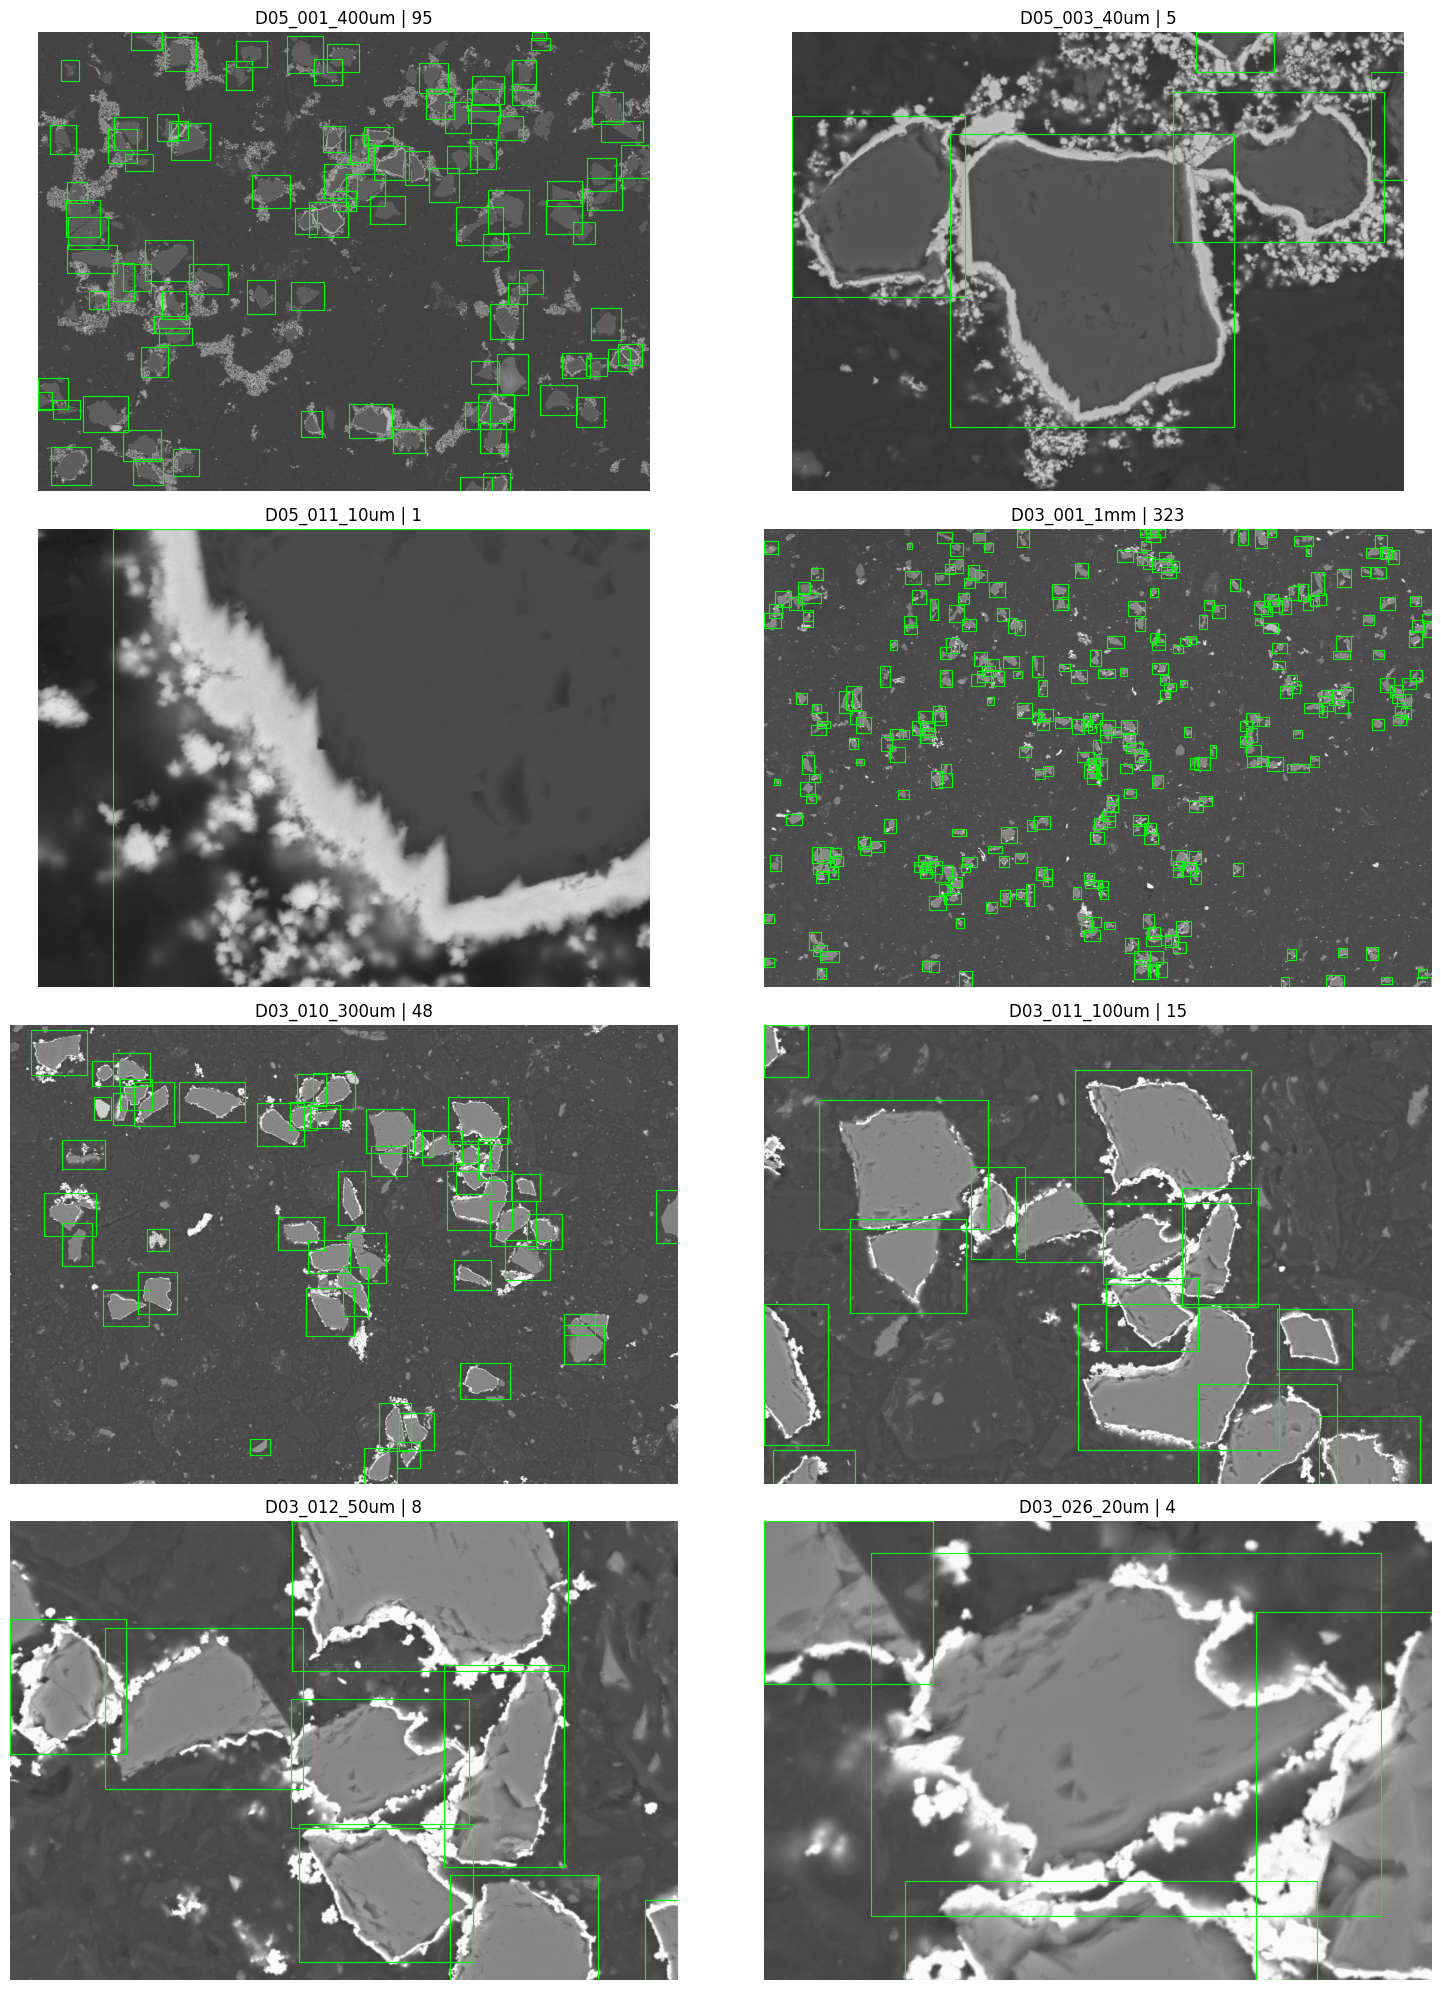

In [21]:
preview = records[:PREVIEW_IMAGES]
if not preview:
    raise ValueError('Нет кадров для просмотра.')
rows = math.ceil(len(preview) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(16, 5 * rows), squeeze=False)
for ax, record in zip(axes.flat, preview):
    with Image.open(record['image']) as image:
        ax.imshow(image.convert('RGB'))
    for class_id, xc, yc, width, height in boxes_by_image[record['image']]:
        ax.add_patch(Rectangle(((xc - width / 2) * record['width'], (yc - height / 2) * record['height']),
            width * record['width'], height * record['height'], fill=False, edgecolor='lime', linewidth=0.8))
    ax.set_title(f"{record['name']} | {record['objects']}")
    ax.axis('off')
for ax in list(axes.flat)[len(preview):]:
    ax.axis('off')
plt.tight_layout()
plt.show()


Обучение — в `02_split_and_train_yolo26s.ipynb`.
Новые изображения и одноимённые TXT добавляются в `data/images` и `data/labels`.
